### 30^th^ June 2026

Generate similarity matrix from all to all alignemnts of NLRs genes across across all genomes at Loc 1

In [2]:
import pandas 
import matplotlib 
import numpy 
import openpyxl
import os

In [6]:
workDir="/Users/waweru/Documents/2022/IBSpy_Targets/2024-12-05_5B_Yellow_Rust/2025-07-02_Watkins_assemblies/all2all"
pafFile=f"{workDir}/all_vs_allNLRGeneSeqs_chr5B_Loc1_17PGs+Tsn1.paf"
outPrefix=f"{workDir}/all_vs_allNLRGeneSeqs_chr5B_Loc1_17PGs+Tsn1"


In [7]:
os.chdir(f"{workDir}")

In [8]:
os.getcwd()

'/Users/waweru/Documents/2022/IBSpy_Targets/2024-12-05_5B_Yellow_Rust/2025-07-02_Watkins_assemblies/all2all'

In [9]:
import sys

outputPrefix = "locus_gene_similarity"

!{sys.executable} pafGenSimilarityMatAllvsAllGenes.py "{pafFile}" \
    --prefix "{outPrefix}" \
    --minimum-coverage 70 \
    --minimum-alignment-length 100

Created: /Users/waweru/Documents/2022/IBSpy_Targets/2024-12-05_5B_Yellow_Rust/2025-07-02_Watkins_assemblies/all2all/all_vs_allNLRGeneSeqs_chr5B_Loc1_17PGs+Tsn1.csv
Created: /Users/waweru/Documents/2022/IBSpy_Targets/2024-12-05_5B_Yellow_Rust/2025-07-02_Watkins_assemblies/all2all/all_vs_allNLRGeneSeqs_chr5B_Loc1_17PGs+Tsn1.xlsx
Created: /Users/waweru/Documents/2022/IBSpy_Targets/2024-12-05_5B_Yellow_Rust/2025-07-02_Watkins_assemblies/all2all/all_vs_allNLRGeneSeqs_chr5B_Loc1_17PGs+Tsn1_heatmap.png


### Creating the excel file from the paf for use in generating the custom riaprian plots

In [12]:
import pandas as pd
from pathlib import Path

pafFile=f"{workDir}/all_vs_allNLRGeneSeqs_chr5B_Loc1_17PGs+Tsn1.paf"
excelFile = f"{workDir}/all_vs_allNLRGeneSeqs_chr5B_Loc1_17PGs+Tsn1_paf.xlsx"

standard_columns = [
    "query",
    "query_length",
    "query_start",
    "query_end",
    "strand",
    "target",
    "target_length",
    "target_start",
    "target_end",
    "matching_bases",
    "alignment_length",
    "mapping_quality"
]

paf = pd.read_csv(
    pafFile,
    sep="\t",
    header=None
)

# Name the 12 mandatory columns and any additional optional-tag columns
extra_columns = [
    f"optional_tag_{i + 1}"
    for i in range(max(0, paf.shape[1] - 12))
]

paf.columns = standard_columns + extra_columns

paf["identity_percent"] = (
    100 * paf["matching_bases"] / paf["alignment_length"]
).round(2)

paf["query_coverage_percent"] = (
    100
    * (paf["query_end"] - paf["query_start"])
    / paf["query_length"]
).round(2)

paf["target_coverage_percent"] = (
    100
    * (paf["target_end"] - paf["target_start"])
    / paf["target_length"]
).round(2)

paf.to_excel(
    excelFile,
    index=False,
    sheet_name="PAF alignments"
)

print(f"Created: {excelFile}")

Created: /Users/waweru/Documents/2022/IBSpy_Targets/2024-12-05_5B_Yellow_Rust/2025-07-02_Watkins_assemblies/all2all/all_vs_allNLRGeneSeqs_chr5B_Loc1_17PGs+Tsn1_paf.xlsx


The code below:
 - Reads the original PAF file.
 - Calculates identity as matching bases / alignment length × 100.
 - Calculates coverage relative to the shorter gene.
 - Applies thresholds: 70% coverage and 100 bp alignment length.
 - Finds the best qualifying identity for every gene pair.
 - Adds that value to each corresponding PAF row.
 - Exports both the full table and a filtered table suitable for a ribbon plot

In [14]:
from pathlib import Path

import numpy as np
import pandas as pd


# ------------------------------------------------------------------
# Input, output and filtering parameters
# ------------------------------------------------------------------

minimum_coverage = 70.0
minimum_alignment_length = 100

work_dir = Path(workDir)

paf_file = (
    work_dir
    / "all_vs_allNLRGeneSeqs_chr5B_Loc1_17PGs+Tsn1.paf"
)

excel_file = (
    work_dir
    / "all_vs_allNLRGeneSeqs_chr5B_Loc1_17PGs+Tsn1_with_identity.xlsx"
)


# ------------------------------------------------------------------
# Standard PAF columns
# ------------------------------------------------------------------

paf_columns = [
    "query",
    "query_length",
    "query_start",
    "query_end",
    "strand",
    "target",
    "target_length",
    "target_start",
    "target_end",
    "matching_bases",
    "alignment_length",
    "mapping_quality",
]


# ------------------------------------------------------------------
# Determine the maximum number of columns in the PAF file
#
# PAF files contain 12 compulsory columns followed by a variable
# number of optional minimap2 tags.
# ------------------------------------------------------------------

with paf_file.open("r") as handle:
    column_counts = [
        len(line.rstrip("\n").split("\t"))
        for line in handle
        if line.strip() and not line.startswith("#")
    ]

if not column_counts:
    raise ValueError(f"No alignment records were found in: {paf_file}")

maximum_columns = max(column_counts)

if maximum_columns < 12:
    raise ValueError(
        "The input file has fewer than the 12 compulsory PAF columns."
    )

extra_columns = [
    f"optional_tag_{number}"
    for number in range(1, maximum_columns - 12 + 1)
]

all_columns = paf_columns + extra_columns


# ------------------------------------------------------------------
# Read the PAF file
# ------------------------------------------------------------------

paf = pd.read_csv(
    paf_file,
    sep="\t",
    header=None,
    names=all_columns,
    comment="#",
    low_memory=False,
)

# Make sure the compulsory numeric columns are numeric
numeric_columns = [
    "query_length",
    "query_start",
    "query_end",
    "target_length",
    "target_start",
    "target_end",
    "matching_bases",
    "alignment_length",
    "mapping_quality",
]

for column in numeric_columns:
    paf[column] = pd.to_numeric(
        paf[column],
        errors="raise",
    )


# ------------------------------------------------------------------
# Calculate percentage identity for each PAF alignment
#
# Identity = matching bases / alignment block length × 100
# ------------------------------------------------------------------

alignment_denominator = paf["alignment_length"].replace(0, np.nan)

paf["alignment_identity_percent"] = (
    100
    * paf["matching_bases"]
    / alignment_denominator
).clip(
    lower=0,
    upper=100,
).round(2)


# ------------------------------------------------------------------
# Calculate query and target coverage separately
#
# PAF coordinates are zero-based, half-open coordinates, so:
#
# aligned sequence span = end - start
# ------------------------------------------------------------------

paf["query_aligned_length"] = (
    paf["query_end"] - paf["query_start"]
).clip(lower=0)

paf["target_aligned_length"] = (
    paf["target_end"] - paf["target_start"]
).clip(lower=0)

paf["query_coverage_percent"] = (
    100
    * paf["query_aligned_length"]
    / paf["query_length"].replace(0, np.nan)
).clip(
    lower=0,
    upper=100,
).round(2)

paf["target_coverage_percent"] = (
    100
    * paf["target_aligned_length"]
    / paf["target_length"].replace(0, np.nan)
).clip(
    lower=0,
    upper=100,
).round(2)


# ------------------------------------------------------------------
# Reciprocal coverage is the lower of query and target coverage
#
# An alignment only has high reciprocal coverage when it covers a
# large proportion of both sequences.
# ------------------------------------------------------------------

paf["reciprocal_coverage_percent"] = paf[
    [
        "query_coverage_percent",
        "target_coverage_percent",
    ]
].min(axis=1).round(2)


# ------------------------------------------------------------------
# Apply the filtering thresholds
#
# Both the query and target must have at least 70% coverage, and the
# alignment block must be at least 100 bp long.
# ------------------------------------------------------------------

paf["passes_filter"] = (
    (paf["query_coverage_percent"] >= minimum_coverage)
    & (paf["target_coverage_percent"] >= minimum_coverage)
    & (paf["alignment_length"] >= minimum_alignment_length)
)


# ------------------------------------------------------------------
# Create a direction-independent identifier for each gene pair
#
# For example:
# GeneA versus GeneB
# GeneB versus GeneA
#
# are assigned to the same gene pair.
# ------------------------------------------------------------------

sorted_gene_pairs = np.sort(
    paf[["query", "target"]]
    .astype(str)
    .to_numpy(),
    axis=1,
)

paf["gene_1"] = sorted_gene_pairs[:, 0]
paf["gene_2"] = sorted_gene_pairs[:, 1]


# ------------------------------------------------------------------
# Retain qualifying alignments
# ------------------------------------------------------------------

qualifying_alignments = paf.loc[
    paf["passes_filter"]
].copy()


# ------------------------------------------------------------------
# Identify the best qualifying alignment for each gene pair
#
# Alignments are ranked by:
#   1. Highest percentage identity
#   2. Highest reciprocal coverage
#   3. Longest alignment
#   4. Highest mapping quality
# ------------------------------------------------------------------

best_pair_rows = (
    qualifying_alignments
    .sort_values(
        by=[
            "gene_1",
            "gene_2",
            "alignment_identity_percent",
            "reciprocal_coverage_percent",
            "alignment_length",
            "mapping_quality",
        ],
        ascending=[
            True,
            True,
            False,
            False,
            False,
            False,
        ],
    )
    .drop_duplicates(
        subset=["gene_1", "gene_2"],
        keep="first",
    )
    .copy()
)


# ------------------------------------------------------------------
# Count how many qualifying alignments were found per gene pair
# ------------------------------------------------------------------

qualifying_counts = (
    qualifying_alignments
    .groupby(
        ["gene_1", "gene_2"],
        as_index=False,
    )
    .size()
    .rename(
        columns={
            "size": "qualifying_alignment_count"
        }
    )
)


# ------------------------------------------------------------------
# Make a summary table containing the best identity for each pair
# ------------------------------------------------------------------

best_pair_summary = best_pair_rows[
    [
        "gene_1",
        "gene_2",
        "alignment_identity_percent",
        "query_coverage_percent",
        "target_coverage_percent",
        "reciprocal_coverage_percent",
        "alignment_length",
        "mapping_quality",
    ]
].copy()

best_pair_summary = best_pair_summary.rename(
    columns={
        "alignment_identity_percent":
            "pairwise_identity_percent",
        "query_coverage_percent":
            "best_alignment_query_coverage_percent",
        "target_coverage_percent":
            "best_alignment_target_coverage_percent",
        "reciprocal_coverage_percent":
            "pairwise_reciprocal_coverage_percent",
        "alignment_length":
            "best_alignment_length",
        "mapping_quality":
            "best_alignment_mapping_quality",
    }
)

best_pair_summary = best_pair_summary.merge(
    qualifying_counts,
    on=["gene_1", "gene_2"],
    how="left",
)


# ------------------------------------------------------------------
# Add the best pairwise identity to every PAF row
#
# alignment_identity_percent:
#     identity of that individual PAF alignment
#
# pairwise_identity_percent:
#     highest identity among qualifying alignments for that gene pair
# ------------------------------------------------------------------

pairwise_identity_lookup = best_pair_summary[
    [
        "gene_1",
        "gene_2",
        "pairwise_identity_percent",
        "pairwise_reciprocal_coverage_percent",
    ]
]

paf_with_identity = paf.merge(
    pairwise_identity_lookup,
    on=["gene_1", "gene_2"],
    how="left",
)


# ------------------------------------------------------------------
# Ribbon-plot table containing every qualifying alignment
# ------------------------------------------------------------------

ribbon_all_hits = paf_with_identity.loc[
    paf_with_identity["passes_filter"]
    & (
        paf_with_identity["query"]
        != paf_with_identity["target"]
    )
].copy()


# ------------------------------------------------------------------
# Ribbon-plot table containing one alignment per gene pair
#
# This removes duplicated A→B and B→A alignments from an
# all-versus-all alignment.
# ------------------------------------------------------------------

ribbon_unique_pairs = (
    ribbon_all_hits
    .sort_values(
        by=[
            "gene_1",
            "gene_2",
            "alignment_identity_percent",
            "reciprocal_coverage_percent",
            "alignment_length",
            "mapping_quality",
        ],
        ascending=[
            True,
            True,
            False,
            False,
            False,
            False,
        ],
    )
    .drop_duplicates(
        subset=["gene_1", "gene_2"],
        keep="first",
    )
    .copy()
)


# ------------------------------------------------------------------
# Create a compact table containing the main ribbon-plot columns
# ------------------------------------------------------------------

ribbon_plot_input = ribbon_unique_pairs[
    [
        "query",
        "query_length",
        "query_start",
        "query_end",
        "target",
        "target_length",
        "target_start",
        "target_end",
        "strand",
        "matching_bases",
        "alignment_length",
        "alignment_identity_percent",
        "query_coverage_percent",
        "target_coverage_percent",
        "reciprocal_coverage_percent",
        "mapping_quality",
        "gene_1",
        "gene_2",
    ]
].copy()


# ------------------------------------------------------------------
# Export the results to Excel
# ------------------------------------------------------------------

with pd.ExcelWriter(
    excel_file,
    engine="openpyxl",
) as writer:

    paf_with_identity.to_excel(
        writer,
        sheet_name="All_PAF_alignments",
        index=False,
    )

    ribbon_all_hits.to_excel(
        writer,
        sheet_name="Ribbon_all_hits",
        index=False,
    )

    ribbon_unique_pairs.to_excel(
        writer,
        sheet_name="Ribbon_unique_pairs",
        index=False,
    )

    ribbon_plot_input.to_excel(
        writer,
        sheet_name="Ribbon_plot_input",
        index=False,
    )

    best_pair_summary.to_excel(
        writer,
        sheet_name="Best_pair_summary",
        index=False,
    )


# ------------------------------------------------------------------
# Report the output
# ------------------------------------------------------------------

print(f"Created: {excel_file}")
print(f"Total PAF alignments: {len(paf_with_identity):,}")
print(f"Alignments passing the filters: {len(ribbon_all_hits):,}")
print(f"Unique non-self gene pairs: {len(ribbon_unique_pairs):,}")

Created: /Users/waweru/Documents/2022/IBSpy_Targets/2024-12-05_5B_Yellow_Rust/2025-07-02_Watkins_assemblies/all2all/all_vs_allNLRGeneSeqs_chr5B_Loc1_17PGs+Tsn1_with_identity.xlsx
Total PAF alignments: 3,095
Alignments passing the filters: 1,387
Unique non-self gene pairs: 98


Re-doing the similarity one

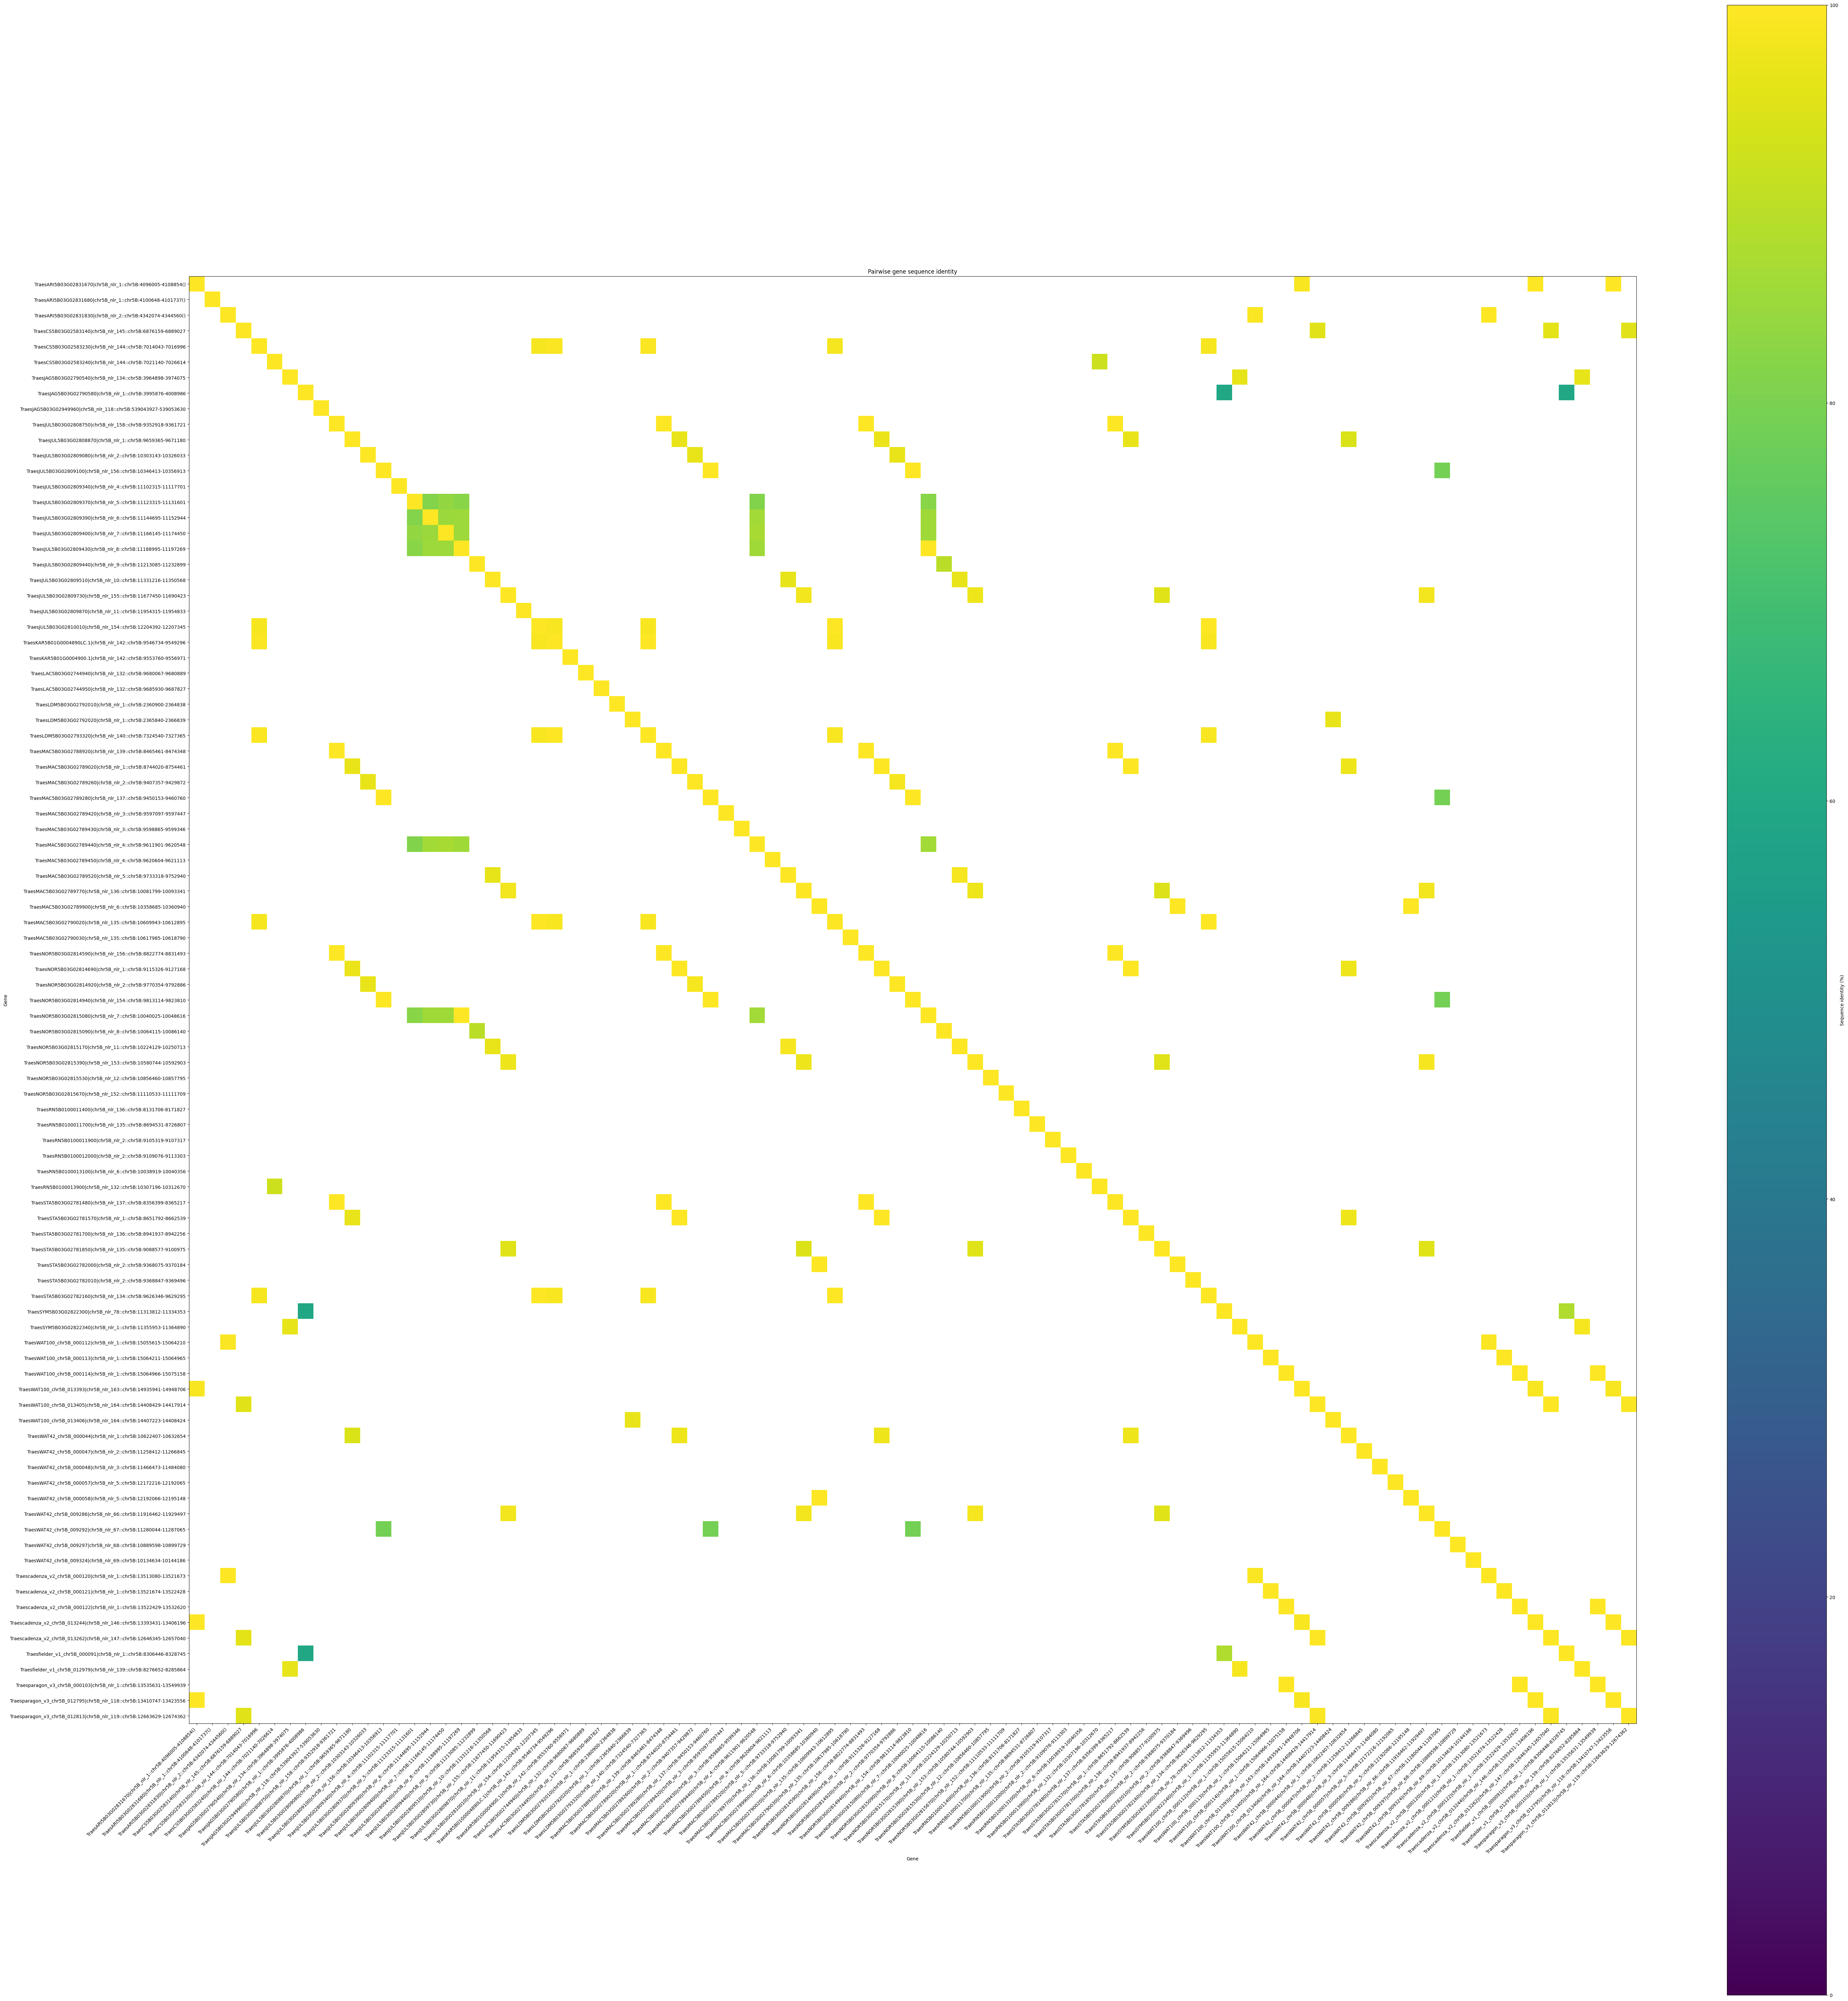

Created Excel workbook: /Users/waweru/Documents/2022/IBSpy_Targets/2024-12-05_5B_Yellow_Rust/2025-07-02_Watkins_assemblies/all2all/all_vs_allNLRGeneSeqs_chr5B_Loc1_17PGs+Tsn1_similarity_v2.xlsx
Created identity matrix: /Users/waweru/Documents/2022/IBSpy_Targets/2024-12-05_5B_Yellow_Rust/2025-07-02_Watkins_assemblies/all2all/all_vs_allNLRGeneSeqs_chr5B_Loc1_17PGs+Tsn1_similarity_identity_matrix_v2.csv
Created heatmap: /Users/waweru/Documents/2022/IBSpy_Targets/2024-12-05_5B_Yellow_Rust/2025-07-02_Watkins_assemblies/all2all/all_vs_allNLRGeneSeqs_chr5B_Loc1_17PGs+Tsn1_similarity_heatmap_v2.png

Total PAF records: 3,095
Qualifying non-self alignments: 1,387
Unique qualifying gene pairs: 98
Genes in the matrix: 93


In [15]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ------------------------------------------------------------------
# Input, output and filtering parameters
# ------------------------------------------------------------------

minimum_coverage = 70.0
minimum_alignment_length = 100

work_dir = Path(workDir)

paf_file = (
    work_dir
    / "all_vs_allNLRGeneSeqs_chr5B_Loc1_17PGs+Tsn1.paf"
)

output_prefix = (
    work_dir
    / "all_vs_allNLRGeneSeqs_chr5B_Loc1_17PGs+Tsn1_similarity"
)

excel_file = Path(f"{output_prefix}_v2.xlsx")
csv_file = Path(f"{output_prefix}_identity_matrix_v2.csv")
heatmap_file = Path(f"{output_prefix}_heatmap_v2.png")


# ------------------------------------------------------------------
# Standard PAF columns
#
# A PAF file contains 12 compulsory columns followed by an optional
# number of minimap2 tags.
# ------------------------------------------------------------------

paf_columns = [
    "query",
    "query_length",
    "query_start",
    "query_end",
    "strand",
    "target",
    "target_length",
    "target_start",
    "target_end",
    "matching_bases",
    "alignment_length",
    "mapping_quality",
]


# ------------------------------------------------------------------
# Determine the maximum number of columns in the PAF file
#
# Different PAF rows can contain different numbers of optional tags.
# This step ensures that all columns can be read correctly.
# ------------------------------------------------------------------

with paf_file.open("r") as handle:
    column_counts = [
        len(line.rstrip("\n").split("\t"))
        for line in handle
        if line.strip() and not line.startswith("#")
    ]

if not column_counts:
    raise ValueError(
        f"No alignment records were found in: {paf_file}"
    )

maximum_columns = max(column_counts)

if maximum_columns < 12:
    raise ValueError(
        "The input file has fewer than the 12 compulsory PAF columns."
    )

extra_columns = [
    f"optional_tag_{number}"
    for number in range(
        1,
        maximum_columns - 12 + 1,
    )
]

all_columns = paf_columns + extra_columns


# ------------------------------------------------------------------
# Read the PAF file
# ------------------------------------------------------------------

paf = pd.read_csv(
    paf_file,
    sep="\t",
    header=None,
    names=all_columns,
    comment="#",
    low_memory=False,
)


# ------------------------------------------------------------------
# Convert the compulsory numeric columns to numeric values
#
# errors="raise" causes the code to stop if an unexpected non-numeric
# value is found in one of these columns.
# ------------------------------------------------------------------

numeric_columns = [
    "query_length",
    "query_start",
    "query_end",
    "target_length",
    "target_start",
    "target_end",
    "matching_bases",
    "alignment_length",
    "mapping_quality",
]

for column in numeric_columns:
    paf[column] = pd.to_numeric(
        paf[column],
        errors="raise",
    )


# ------------------------------------------------------------------
# Calculate percentage identity for every individual alignment
#
# Percentage identity =
# matching bases / alignment block length × 100
#
# The alignment block length includes aligned matches, mismatches
# and gaps.
# ------------------------------------------------------------------

alignment_denominator = paf[
    "alignment_length"
].replace(0, np.nan)

paf["alignment_identity_percent"] = (
    100
    * paf["matching_bases"]
    / alignment_denominator
).clip(
    lower=0,
    upper=100,
).round(2)


# ------------------------------------------------------------------
# Calculate the length of each sequence spanned by the alignment
#
# PAF coordinates are zero-based and half-open. Therefore:
#
# aligned span = end coordinate - start coordinate
# ------------------------------------------------------------------

paf["query_aligned_length"] = (
    paf["query_end"] - paf["query_start"]
).clip(lower=0)

paf["target_aligned_length"] = (
    paf["target_end"] - paf["target_start"]
).clip(lower=0)


# ------------------------------------------------------------------
# Calculate query and target coverage independently
#
# Query coverage =
# aligned query span / total query length × 100
#
# Target coverage =
# aligned target span / total target length × 100
# ------------------------------------------------------------------

paf["query_coverage_percent"] = (
    100
    * paf["query_aligned_length"]
    / paf["query_length"].replace(0, np.nan)
).clip(
    lower=0,
    upper=100,
).round(2)

paf["target_coverage_percent"] = (
    100
    * paf["target_aligned_length"]
    / paf["target_length"].replace(0, np.nan)
).clip(
    lower=0,
    upper=100,
).round(2)


# ------------------------------------------------------------------
# Calculate reciprocal coverage
#
# Reciprocal coverage is the lower of the query and target coverage.
#
# For example:
#
# Query coverage  = 95%
# Target coverage = 72%
#
# Reciprocal coverage = 72%
#
# This provides one conservative coverage value for the alignment.
# ------------------------------------------------------------------

paf["reciprocal_coverage_percent"] = paf[
    [
        "query_coverage_percent",
        "target_coverage_percent",
    ]
].min(axis=1).round(2)


# ------------------------------------------------------------------
# Apply the filtering thresholds
#
# An alignment is retained only when:
#
# 1. Query coverage is at least 70%
# 2. Target coverage is at least 70%
# 3. Alignment block length is at least 100 bp
# ------------------------------------------------------------------

paf["passes_filter"] = (
    (paf["query_coverage_percent"] >= minimum_coverage)
    & (paf["target_coverage_percent"] >= minimum_coverage)
    & (
        paf["alignment_length"]
        >= minimum_alignment_length
    )
)


# ------------------------------------------------------------------
# Create a direction-independent identifier for every gene pair
#
# All-versus-all alignment normally produces both:
#
# GeneA -> GeneB
# GeneB -> GeneA
#
# Sorting the names allows both directions to be treated as the same
# gene pair.
# ------------------------------------------------------------------

sorted_gene_pairs = np.sort(
    paf[
        [
            "query",
            "target",
        ]
    ]
    .astype(str)
    .to_numpy(),
    axis=1,
)

paf["gene_1"] = sorted_gene_pairs[:, 0]
paf["gene_2"] = sorted_gene_pairs[:, 1]


# ------------------------------------------------------------------
# Retain qualifying non-self alignments
#
# Self-alignments are not used when selecting the best comparison
# between two different genes. The matrix diagonal will later be
# assigned 100% identity.
# ------------------------------------------------------------------

qualifying_alignments = paf.loc[
    paf["passes_filter"]
    & (paf["query"] != paf["target"])
].copy()


# ------------------------------------------------------------------
# Select the best qualifying alignment for every gene pair
#
# Alignments are ranked in this order:
#
# 1. Highest percentage identity
# 2. Highest reciprocal coverage
# 3. Longest alignment block
# 4. Highest mapping quality
#
# Only the highest-ranked alignment is retained for each unordered
# gene pair.
# ------------------------------------------------------------------

best_pair_alignments = (
    qualifying_alignments
    .sort_values(
        by=[
            "gene_1",
            "gene_2",
            "alignment_identity_percent",
            "reciprocal_coverage_percent",
            "alignment_length",
            "mapping_quality",
        ],
        ascending=[
            True,
            True,
            False,
            False,
            False,
            False,
        ],
    )
    .drop_duplicates(
        subset=[
            "gene_1",
            "gene_2",
        ],
        keep="first",
    )
    .copy()
)


# ------------------------------------------------------------------
# Count the number of qualifying alignments for each gene pair
#
# This is useful when a gene pair has several alternative or
# fragmented qualifying alignments.
# ------------------------------------------------------------------

qualifying_alignment_counts = (
    qualifying_alignments
    .groupby(
        [
            "gene_1",
            "gene_2",
        ],
        as_index=False,
    )
    .size()
    .rename(
        columns={
            "size": "qualifying_alignment_count"
        }
    )
)


# ------------------------------------------------------------------
# Create a summary table for the best alignment of each gene pair
# ------------------------------------------------------------------

best_pair_summary = best_pair_alignments[
    [
        "gene_1",
        "gene_2",
        "query",
        "target",
        "strand",
        "query_length",
        "target_length",
        "query_start",
        "query_end",
        "target_start",
        "target_end",
        "matching_bases",
        "alignment_length",
        "alignment_identity_percent",
        "query_coverage_percent",
        "target_coverage_percent",
        "reciprocal_coverage_percent",
        "mapping_quality",
    ]
].copy()

best_pair_summary = best_pair_summary.rename(
    columns={
        "alignment_identity_percent":
            "pairwise_identity_percent"
    }
)

best_pair_summary = best_pair_summary.merge(
    qualifying_alignment_counts,
    on=[
        "gene_1",
        "gene_2",
    ],
    how="left",
)


# ------------------------------------------------------------------
# Obtain a complete list of genes from both query and target columns
#
# This ensures that genes without qualifying matches are still
# included in the final matrix.
# ------------------------------------------------------------------

genes = sorted(
    set(paf["query"].astype(str))
    .union(
        set(paf["target"].astype(str))
    )
)


# ------------------------------------------------------------------
# Create an empty percentage-identity matrix
#
# Rows and columns contain the same genes.
# Missing comparisons are initially stored as NaN.
# ------------------------------------------------------------------

identity_matrix = pd.DataFrame(
    np.nan,
    index=genes,
    columns=genes,
    dtype=float,
)

identity_matrix.index.name = "gene"
identity_matrix.columns.name = "gene"


# ------------------------------------------------------------------
# Create a reciprocal-coverage matrix
#
# This matrix records the reciprocal coverage associated with the
# best alignment selected for each gene pair.
# ------------------------------------------------------------------

reciprocal_coverage_matrix = pd.DataFrame(
    np.nan,
    index=genes,
    columns=genes,
    dtype=float,
)

reciprocal_coverage_matrix.index.name = "gene"
reciprocal_coverage_matrix.columns.name = "gene"


# ------------------------------------------------------------------
# Assign self-comparisons
#
# Every gene is considered 100% identical to itself and has 100%
# reciprocal coverage on the matrix diagonal.
# ------------------------------------------------------------------

np.fill_diagonal(
    identity_matrix.values,
    100.0,
)

np.fill_diagonal(
    reciprocal_coverage_matrix.values,
    100.0,
)


# ------------------------------------------------------------------
# Add each best gene-pair alignment to both halves of the matrices
#
# This produces symmetrical matrices:
#
# matrix[GeneA, GeneB] = matrix[GeneB, GeneA]
# ------------------------------------------------------------------

for row in best_pair_summary.itertuples(index=False):

    gene_1 = row.gene_1
    gene_2 = row.gene_2

    identity = row.pairwise_identity_percent
    reciprocal_coverage = row.reciprocal_coverage_percent

    identity_matrix.loc[
        gene_1,
        gene_2,
    ] = identity

    identity_matrix.loc[
        gene_2,
        gene_1,
    ] = identity

    reciprocal_coverage_matrix.loc[
        gene_1,
        gene_2,
    ] = reciprocal_coverage

    reciprocal_coverage_matrix.loc[
        gene_2,
        gene_1,
    ] = reciprocal_coverage


# ------------------------------------------------------------------
# Round the matrices for presentation
# ------------------------------------------------------------------

identity_matrix = identity_matrix.round(2)

reciprocal_coverage_matrix = (
    reciprocal_coverage_matrix.round(2)
)


# ------------------------------------------------------------------
# Plot the percentage-identity matrix as a heatmap
# ------------------------------------------------------------------

number_of_genes = len(identity_matrix)

figure_size = max(
    8,
    number_of_genes * 0.65,
)

fig, ax = plt.subplots(
    figsize=(
        figure_size,
        figure_size,
    )
)

# Hide missing values from the heatmap
masked_identity_matrix = np.ma.masked_invalid(
    identity_matrix.to_numpy(dtype=float)
)

image = ax.imshow(
    masked_identity_matrix,
    vmin=0,
    vmax=100,
    aspect="equal",
)

ax.set_xticks(
    range(number_of_genes)
)

ax.set_yticks(
    range(number_of_genes)
)

ax.set_xticklabels(
    identity_matrix.columns,
    rotation=45,
    ha="right",
)

ax.set_yticklabels(
    identity_matrix.index,
)

ax.set_xlabel(
    "Gene"
)

ax.set_ylabel(
    "Gene"
)

ax.set_title(
    "Pairwise gene sequence identity"
)

colour_bar = fig.colorbar(
    image,
    ax=ax,
)

colour_bar.set_label(
    "Sequence identity (%)"
)


# ------------------------------------------------------------------
# Add identity values inside the heatmap cells
#
# Values are only added when there are 30 or fewer genes, because
# larger matrices become difficult to read when every cell is
# labelled.
# ------------------------------------------------------------------

if number_of_genes <= 30:

    annotation_font_size = max(
        5,
        10 - number_of_genes * 0.12,
    )

    for row_number in range(number_of_genes):

        for column_number in range(number_of_genes):

            value = identity_matrix.iloc[
                row_number,
                column_number,
            ]

            if pd.notna(value):

                ax.text(
                    column_number,
                    row_number,
                    f"{value:.1f}",
                    ha="center",
                    va="center",
                    fontsize=annotation_font_size,
                )


fig.tight_layout()

fig.savefig(
    heatmap_file,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------------
# Export the percentage-identity matrix as CSV
# ------------------------------------------------------------------

identity_matrix.to_csv(
    csv_file,
    na_rep="NA",
)


# ------------------------------------------------------------------
# Export all results to one Excel workbook
# ------------------------------------------------------------------

with pd.ExcelWriter(
    excel_file,
    engine="openpyxl",
) as writer:

    identity_matrix.to_excel(
        writer,
        sheet_name="Percentage_identity_matrix",
        na_rep="NA",
    )

    reciprocal_coverage_matrix.to_excel(
        writer,
        sheet_name="Reciprocal_coverage_matrix",
        na_rep="NA",
    )

    best_pair_summary.to_excel(
        writer,
        sheet_name="Best_pair_summary",
        index=False,
    )

    qualifying_alignments.to_excel(
        writer,
        sheet_name="Qualifying_alignments",
        index=False,
    )

    paf.to_excel(
        writer,
        sheet_name="All_PAF_alignments",
        index=False,
    )


# ------------------------------------------------------------------
# Report the output files and summary statistics
# ------------------------------------------------------------------

print(f"Created Excel workbook: {excel_file}")
print(f"Created identity matrix: {csv_file}")
print(f"Created heatmap: {heatmap_file}")

print()
print(f"Total PAF records: {len(paf):,}")
print(
    "Qualifying non-self alignments: "
    f"{len(qualifying_alignments):,}"
)
print(
    "Unique qualifying gene pairs: "
    f"{len(best_pair_summary):,}"
)
print(f"Genes in the matrix: {len(genes):,}")